# Лабораторная работа № 3. Логистическая регрессия на реальных данных
## Предсказание лишнего веса у школьников с помощью логистической регрессии

Продолжаю работать с данными первой лабораторной `HW_001_001.csv`. В этой работе предсказываю один из двух классов в столбце `overweight`: нормальный или лишний вес.

## 1. Данные, задача и начальные гипотезы

**Источник** Это набор данных, который использовался в первой и второй лабораторных. В исходном CSV 1089 наблюдений и 22 столбца. Данные собраны в 39 школах Барселоны с января 2012 года по март 2013 года.

**Объект:** один ребёнок и известные для него характеристики.

**Цель** столбец `overweight`. Значение «лишний вес» (`Overweight`) кодирую как 1, значение «нормальный вес» (`Normal weight`) кодирую как 0.

**Признаки** возраст, возраст поступления в школу, пол, класс, весовая категория при рождении, кормление грудью, курение матери, образование родителей, братья и сёстры, NO2 дома и в классе, социальные индексы, озеленение, шум и осадки.

`react`, `correct` и `omissions` не использую. Это результаты теста внимания.

**Возможные ошибки.** Ложноотрицательная ошибка означает, что модель не заметила ребёнка с лишним весом. Для условной предварительной проверки эта ошибка неприятнее. Ложноположительная ошибка приведёт к лишней дополнительной проверке. 



### Гипотезы

1. Процент детей с лишним весом среди мальчиков и среди девочек различается.
2. Категориальные признаки семьи и раннего развития улучшат модель
3. Из-за меньшей доли детей с лишним весом обычный порог 0.5 будет давать слишком много ложноотрицательных ошибок. `class_weight='balanced'` должен повысить долю найденных детей с лишним весом.
4. Слишком сильная регуляризация тоже может ухудшить результат
5. Если уменьшить порог классификации, модель найдёт больше детей с лишним весом, но одновременно чаще будет ошибочно относить детей с нормальным весом к классу «лишний вес». Проверим это на проверочной выборке.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    confusion_matrix, classification_report,
    roc_curve, precision_recall_curve, make_scorer
)
from sklearn.model_selection import (
    train_test_split, StratifiedKFold,
    cross_validate, cross_val_predict
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

sns.set_theme()
pd.set_option('display.max_columns', 50)

RANDOM_STATE = 2026
CV_STATE = 42
ARTIFACTS = Path('lab3_artifacts')
DATA_PATH = ARTIFACTS / 'HW_001_001.csv'

df = pd.read_csv(DATA_PATH)
print('Исходная таблица:', df.shape)
print('Полные дубликаты:', df.duplicated().sum())
pd.DataFrame({'Тип': df.dtypes, 'Пропусков': df.isna().sum()})

Исходная таблица: (1089, 22)
Полные дубликаты: 0


,Тип,Пропусков
react,float64,5
correct,float64,5
omissions,float64,5
no2_class,float64,0
no2_home,float64,0
age,float64,0
age0,float64,7
sex,object,0
grade,object,0
overweight,object,26


,Количество,"Доля, %"
overweight,,
Нормальный вес,807,74.10
Лишний вес,256,23.51
NaN,26,2.39


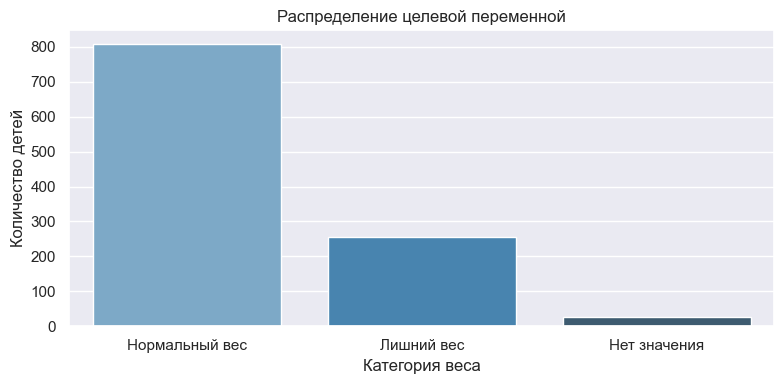

In [2]:
target_counts = df['overweight'].value_counts(dropna=False)
target_table = pd.DataFrame({
    'Количество': target_counts,
    'Доля, %': (target_counts / len(df) * 100).round(2)
})
target_table = target_table.rename(index={
    'Normal weight': 'Нормальный вес',
    'Overweight': 'Лишний вес'
})
display(target_table)

plot_counts = (
    df['overweight']
    .replace({'Normal weight': 'Нормальный вес', 'Overweight': 'Лишний вес'})
    .fillna('Нет значения')
    .value_counts()
)
plt.figure(figsize=(8, 4))
sns.barplot(x=plot_counts.index, y=plot_counts.values, hue=plot_counts.index,
            legend=False, palette='Blues_d')
plt.title('Распределение целевой переменной')
plt.xlabel('Категория веса')
plt.ylabel('Количество детей')
plt.tight_layout()
plt.show()

**Наблюдение.** В целевой переменной 26 пропусков. Их нельзя заполнять, потому что это неизвестные правильные ответы. После удаления этих строк остаётся 1063 объекта: 807 с нормальным весом и 256 с лишним весом. Доля объектов с лишним весом составляет около 24%, поэтому оценка модели только по доле правильных ответов может вводить в заблуждение.

## 2. Разделение данных

Сначала отделяю 20% строк для финальной проверки. Использую `stratify=y`, чтобы доли классов в обучающей и тестовой выборках были близкими. Тестовая выборка больше не используется до выбора признаков, `C`, `class_weight` и порога.

Все пропуски в признаках заполняются внутри конвейера `Pipeline`. Значит, медианы, самые частые категории и параметры масштабирования на каждом разбиении вычисляются только по его обучающей части.

In [3]:
data = df[df['overweight'].notna()].copy()

num_columns = [
    'no2_class', 'no2_home', 'age', 'age0',
    'siblings_old', 'siblings_young', 'sev_home', 'green_home',
    'noise_school', 'sev_school', 'precip'
]
cat_columns = [
    'sex', 'grade', 'lbweight', 'breastfeed',
    'msmoke', 'meducation', 'feducation'
]
feature_columns = num_columns + cat_columns

X = data[feature_columns].copy()
y = data['overweight'].eq('Overweight').astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

split_balance = pd.DataFrame({
    'Часть': ['Все данные', 'Обучающая выборка', 'Тестовая выборка'],
    'Объектов': [len(y), len(y_train), len(y_test)],
    'Лишний вес': [y.sum(), y_train.sum(), y_test.sum()],
    'Доля лишнего веса': [y.mean(), y_train.mean(), y_test.mean()]
})
split_balance['Доля лишнего веса'] = split_balance['Доля лишнего веса'].round(3)
display(split_balance)

assert len(X_train.index.intersection(X_test.index)) == 0
assert X_train.index.equals(y_train.index)
assert len(feature_columns) == 18

,Часть,Объектов,Лишний вес,Доля лишнего веса
0,Все данные,1063,256,0.241
1,Обучающая выборка,850,205,0.241
2,Тестовая выборка,213,51,0.239


In [4]:
train_sex = pd.crosstab(
    X_train['sex'], y_train,
    normalize='index'
).rename(columns={0: 'Нормальный вес', 1: 'Лишний вес'})
display((train_sex * 100).round(1).rename_axis('Пол'))

overweight,Нормальный вес,Лишний вес
Пол,,
Female,79.9,20.1
Male,71.7,28.3


В обучающей выборке доля детей с лишним весом у мальчиков выше, чем у девочек, поэтому для модели с одним признаком беру `sex` (пол). Разница между группами сама по себе не доказывает причинное влияние пола.

## 3. Предобработка и правила сравнения

Для числовых признаков использую медиану и `StandardScaler`. Для категориальных признаков использую самое частое значение и `OneHotEncoder`. Такой порядок показан на практике по логистической регрессии.

Внутри обучающей выборки задаю пять одинаковых стратифицированных разбиений. Основные метрики:

- **точность (`precision`)** - какая доля детей, которым модель предсказала лишний вес, действительно имеет лишний вес;
- **полнота (`recall`)** - какую долю детей с лишним весом модель смогла найти;
- **F1-мера** - баланс точности и полноты;
- **ROC-AUC** - качество ранжирования двух классов;
- **средняя точность (AP)** - сводная оценка для кривой «точность-полнота». В таблицах она названа PR-AUC, но рассчитана через `average_precision_score`, а не как трапецеидальная площадь под кривой.

Главный ориентир для выбора - полнота и PR-AUC. Одновременно контролирую F1-меру, потому что получить полноту 1 можно, просто отнеся все строки к классу «лишний вес».

In [5]:
def make_preprocessor(numeric, categorical=None):
    categorical = [] if categorical is None else categorical
    branches = []

    if numeric:
        num_pipe = Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ])
        branches.append(('num', num_pipe, numeric))

    if categorical:
        cat_pipe = Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OneHotEncoder(
                drop='if_binary', handle_unknown='ignore',
                sparse_output=False
            ))
        ])
        branches.append(('cat', cat_pipe, categorical))

    return ColumnTransformer(branches, remainder='drop')


def make_logistic(numeric, categorical=None, C=1.0, class_weight=None):
    return Pipeline([
        ('preprocessors', make_preprocessor(numeric, categorical)),
        ('model', LogisticRegression(
            C=C,
            penalty='l2',
            class_weight=class_weight,
            max_iter=2000,
            random_state=RANDOM_STATE
        ))
    ])


scoring = {
    'accuracy': 'accuracy',
    'precision': make_scorer(precision_score, zero_division=0),
    'recall': make_scorer(recall_score, zero_division=0),
    'f1': make_scorer(f1_score, zero_division=0),
    'roc_auc': 'roc_auc',
    'pr_auc': 'average_precision'
}
cv_rule = StratifiedKFold(n_splits=5, shuffle=True, random_state=CV_STATE)

cv_rows = []
model_templates = {}


def remember_cv(name, estimator, hypothesis):
    scores = cross_validate(
        estimator, X_train, y_train,
        cv=cv_rule, scoring=scoring,
        return_train_score=False, error_score='raise'
    )
    row = {'Модель': name, 'Гипотеза': hypothesis}
    for metric in scoring:
        values = scores[f'test_{metric}']
        row[metric] = values.mean()
        row[f'{metric}_std'] = values.std(ddof=1)
    cv_rows.append(row)
    model_templates[name] = estimator
    return row


def compact_cv_table(names):
    table = pd.DataFrame(cv_rows).set_index('Модель').loc[names]
    columns = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'pr_auc']
    return table[columns].rename(columns={
        'accuracy': 'Доля правильных ответов',
        'precision': 'Точность',
        'recall': 'Полнота',
        'f1': 'F1-мера',
        'roc_auc': 'ROC-AUC',
        'pr_auc': 'PR-AUC'
    }).round(3)


def report_table(y_true, y_pred):
    report = classification_report(
        y_true, y_pred,
        target_names=['Нормальный вес', 'Лишний вес'],
        output_dict=True, zero_division=0
    )
    table = pd.DataFrame(report).T
    return table.rename(
        index={
            'accuracy': 'Доля правильных ответов',
            'macro avg': 'Среднее по классам',
            'weighted avg': 'Взвешенное среднее'
        },
        columns={
            'precision': 'Точность',
            'recall': 'Полнота',
            'f1-score': 'F1-мера',
            'support': 'Количество'
        }
    ).round(3)

## 4. Фиктивная модель, один признак и базовая логистическая регрессия

Сравниваю четыре первых варианта:

1. `DummyClassifier` всегда выбирает самый частый класс.
2. Логистическая регрессия только по `sex`.
3. Логистическая регрессия только по числовым признакам.
4. Базовая логистическая регрессия по всем 18 признакам.

In [6]:
DUMMY = 'Фиктивная модель: самый частый класс'
ONE = 'Один признак: пол'
NUMERIC = 'Только числовые признаки'
BASELINE = 'Базовая модель: все признаки'

remember_cv(
    DUMMY,
    DummyClassifier(strategy='most_frequent', random_state=RANDOM_STATE),
    'Проверка, полезнее ли модель самого частого класса'
)
remember_cv(
    ONE,
    make_logistic([], ['sex']),
    'Один признак даст небольшую часть качества'
)
remember_cv(
    NUMERIC,
    make_logistic(num_columns, []),
    'Числовые признаки содержат полезный сигнал'
)
remember_cv(
    BASELINE,
    make_logistic(num_columns, cat_columns),
    'Категории дополнят числовые признаки'
)

first_models = [DUMMY, ONE, NUMERIC, BASELINE]
compact_cv_table(first_models)

,Доля правильных ответов,Точность,Полнота,F1-мера,ROC-AUC,PR-AUC
Модель,,,,,,
Фиктивная модель: самый частый класс,0.759,0.000,0.000,0.000,0.500,0.241
Один признак: пол,0.759,0.000,0.000,0.000,0.556,0.268
Только числовые признаки,0.758,0.000,0.000,0.000,0.555,0.320
Базовая модель: все признаки,0.742,0.306,0.049,0.083,0.606,0.337


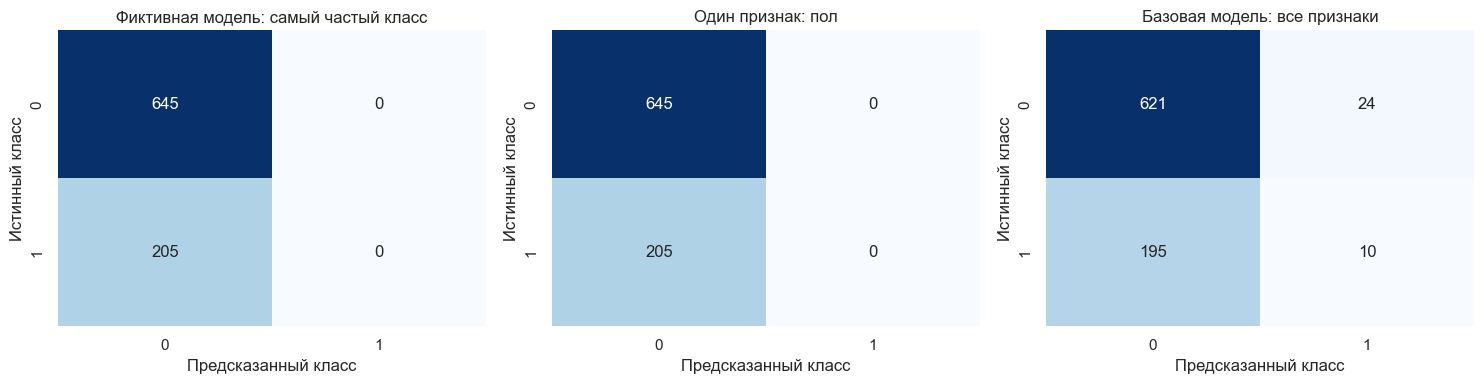

Отчёт по базовой модели на вневыборочных прогнозах обучающей выборки:


,Точность,Полнота,F1-мера,Количество
Нормальный вес,0.761,0.963,0.850,645.000
Лишний вес,0.294,0.049,0.084,205.000
Доля правильных ответов,0.742,0.742,0.742,0.742
Среднее по классам,0.528,0.506,0.467,850.000
Взвешенное среднее,0.648,0.742,0.665,850.000


In [7]:
oof_predictions = {}
for name in [DUMMY, ONE, BASELINE]:
    oof_predictions[name] = cross_val_predict(
        model_templates[name], X_train, y_train,
        cv=cv_rule, method='predict'
    )

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, name in zip(axes, [DUMMY, ONE, BASELINE]):
    matrix = confusion_matrix(y_train, oof_predictions[name])
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax)
    ax.set_title(name)
    ax.set_xlabel('Предсказанный класс')
    ax.set_ylabel('Истинный класс')
plt.tight_layout()
plt.show()

print('Отчёт по базовой модели на вневыборочных прогнозах обучающей выборки:')
display(report_table(y_train, oof_predictions[BASELINE]))

**Результат первых моделей.** Фиктивная модель получает долю правильных ответов около 0.76, но её полнота и F1-мера для класса «лишний вес» равны нулю. Высокая доля правильных ответов объясняется только тем, что нормальный вес встречается чаще.

Модель по одному признаку `sex` тоже никому не предсказывает лишний вес при пороге 0.5. При этом её ROC-AUC немного выше 0.5. Значит, в признаке есть слабый сигнал для ранжирования, но его недостаточно для уверенного решения.

Числовая модель почти повторяет поведение фиктивной модели. Добавление категорий повышает ROC-AUC примерно до 0.61 и PR-AUC примерно до 0.34, но базовая модель всё ещё пропускает почти всех детей с лишним весом. Модель узнала немного полезного, однако порог 0.5 и дисбаланс классов мешают использовать этот сигнал.

## 5. Категории, баланс классов и параметр C

Первая гипотеза подтвердилась частично: категории улучшили ранжирование, но не решили проблему низкой полноты. Поэтому проверяю `class_weight='balanced'`. В этом режиме ошибки более редкого класса получают больший вес.

Одновременно сравниваю четыре значения `C`. Чем меньше `C`, тем сильнее L2-регуляризация. Все варианты сравниваются на тех же пяти разбиениях обучающей выборки.

In [8]:
balanced_names = []
for C in [0.01, 0.1, 1.0, 10.0]:
    name = f'Взвешенные классы, C={C:g}'
    balanced_names.append(name)
    remember_cv(
        name,
        make_logistic(
            num_columns, cat_columns,
            C=C, class_weight='balanced'
        ),
        'Проверка веса классов и силы L2-регуляризации'
    )

compact_cv_table([BASELINE] + balanced_names)

,Доля правильных ответов,Точность,Полнота,F1-мера,ROC-AUC,PR-AUC
Модель,,,,,,
Базовая модель: все признаки,0.742,0.306,0.049,0.083,0.606,0.337
"Взвешенные классы, C=0.01",0.596,0.310,0.546,0.395,0.604,0.357
"Взвешенные классы, C=0.1",0.604,0.314,0.541,0.396,0.606,0.348
"Взвешенные классы, C=1",0.602,0.313,0.541,0.396,0.608,0.342
"Взвешенные классы, C=10",0.602,0.312,0.537,0.394,0.608,0.340


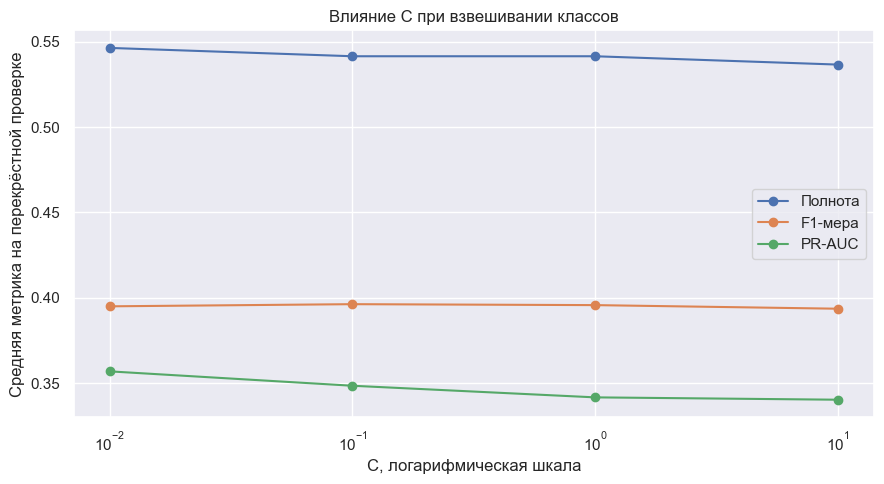

In [9]:
balanced_table = pd.DataFrame(cv_rows).set_index('Модель').loc[balanced_names].copy()
balanced_table['C'] = [0.01, 0.1, 1.0, 10.0]

plt.figure(figsize=(9, 5))
for metric, label in [('recall', 'Полнота'), ('f1', 'F1-мера'), ('pr_auc', 'PR-AUC')]:
    plt.plot(balanced_table['C'], balanced_table[metric], marker='o', label=label)
plt.xscale('log')
plt.xlabel('C, логарифмическая шкала')
plt.ylabel('Средняя метрика на перекрёстной проверке')
plt.title('Влияние C при взвешивании классов')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

**Результат.** `class_weight='balanced'` сильно меняет решение: средняя полнота поднимается примерно с 0.05 до 0.54, а F1-мера - примерно с 0.08 до 0.40. Цена улучшения - снижение доли правильных ответов и точности, потому что модель чаще предсказывает лишний вес.

Разница между значениями `C` небольшая и сопоставима с разбросом между разбиениями. Вариант `C=0.01` даёт самые высокие среднюю полноту и PR-AUC при почти такой же F1-мере, поэтому выбираю его. Это не доказательство, что 0.01 является универсально лучшим значением.

## 6. Выбор порога только по обучающей выборке

Для выбранного варианта получаю вневыборочные вероятности через `cross_val_predict`: каждая строка обучающей выборки предсказана моделью, которая не обучалась на этой строке.

До просмотра тестовой выборки задаю правило: хочу найти в обучающей выборке не менее 70% детей с лишним весом. Среди порогов с полнотой не ниже 0.70 выбираю тот, у которого максимальная точность. 

In [10]:
FINAL_C = 0.01
final_template = make_logistic(
    num_columns, cat_columns,
    C=FINAL_C, class_weight='balanced'
)

oof_probability = cross_val_predict(
    final_template, X_train, y_train,
    cv=cv_rule, method='predict_proba'
)[:, 1]

precision_values, recall_values, thresholds = precision_recall_curve(
    y_train, oof_probability
)
threshold_table = pd.DataFrame({
    'threshold': thresholds,
    'precision': precision_values[:-1],
    'recall': recall_values[:-1]
})
threshold_table['f1'] = (
    2 * threshold_table['precision'] * threshold_table['recall'] /
    (threshold_table['precision'] + threshold_table['recall'] + 1e-12)
)

suitable = threshold_table[threshold_table['recall'] >= 0.70]
chosen_row = suitable.sort_values(
    ['precision', 'threshold'], ascending=False
).iloc[0]
chosen_threshold = float(chosen_row['threshold'])

print('Выбранный порог:', round(chosen_threshold, 3))
display(
    chosen_row.rename(index={
        'threshold': 'Порог', 'precision': 'Точность',
        'recall': 'Полнота', 'f1': 'F1-мера'
    }).to_frame('Значение').round(3)
)

Выбранный порог: 0.462


,Значение
Порог,0.462
Точность,0.284
Полнота,0.702
F1-мера,0.404


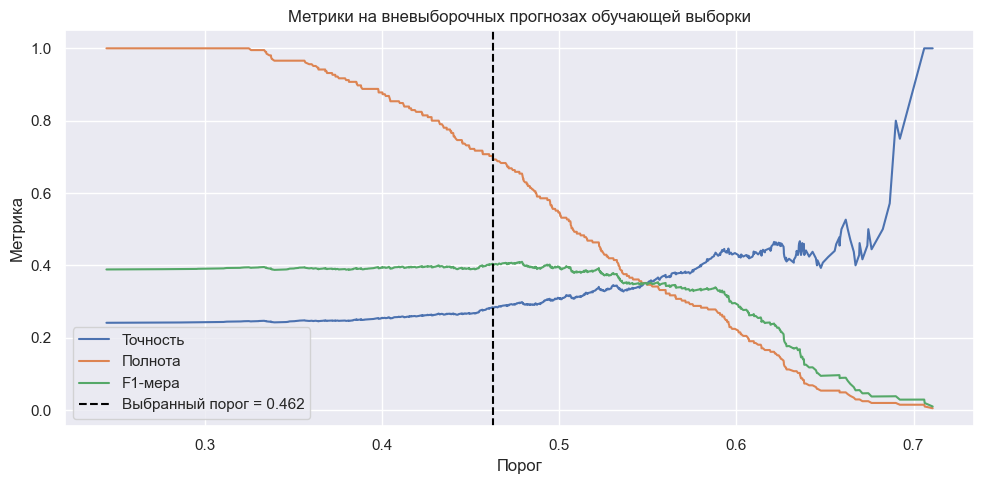

,Порог,Точность,Полнота,F1-мера
0,0.500,0.309,0.546,0.395
1,0.462,0.284,0.702,0.404


In [11]:
plt.figure(figsize=(10, 5))
plt.plot(threshold_table['threshold'], threshold_table['precision'], label='Точность')
plt.plot(threshold_table['threshold'], threshold_table['recall'], label='Полнота')
plt.plot(threshold_table['threshold'], threshold_table['f1'], label='F1-мера')
plt.axvline(chosen_threshold, color='black', linestyle='--',
            label=f'Выбранный порог = {chosen_threshold:.3f}')
plt.xlabel('Порог')
plt.ylabel('Метрика')
plt.title('Метрики на вневыборочных прогнозах обучающей выборки')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

pred_05 = (oof_probability >= 0.5).astype(int)
pred_chosen = (oof_probability >= chosen_threshold).astype(int)
threshold_comparison = pd.DataFrame([
    {
        'Порог': 0.5,
        'Точность': precision_score(y_train, pred_05, zero_division=0),
        'Полнота': recall_score(y_train, pred_05),
        'F1-мера': f1_score(y_train, pred_05)
    },
    {
        'Порог': chosen_threshold,
        'Точность': precision_score(y_train, pred_chosen, zero_division=0),
        'Полнота': recall_score(y_train, pred_chosen),
        'F1-мера': f1_score(y_train, pred_chosen)
    }
])
threshold_comparison.round(3)

**Результат.** Выбранный порог получается ниже 0.5. На вневыборочных прогнозах обучающей выборки он достигает заданной полноты около 0.70, но точность остаётся низкой. Гипотеза подтвердилась: уменьшение порога сокращает число пропущенных детей с лишним весом, но увеличивает число ложных тревог.

## 7. Выбор финальной модели

Перед проверкой на тестовой выборке был выбран итоговый вариант модели:

- все 18 выбранных признаков
- медиана и стандартизация для чисел
- самое частое значение и кодирование категорий отдельными бинарными столбцами
- `LogisticRegression` с L2-регуляризацией
- `C=0.01`
- `class_weight='balanced'`

Теперь обучаю модели на всей обучающей выборке и один раз оцениваю их на тестовой выборке.

In [12]:
dummy_model = DummyClassifier(
    strategy='most_frequent', random_state=RANDOM_STATE
).fit(X_train, y_train)
baseline_model = make_logistic(
    num_columns, cat_columns
).fit(X_train, y_train)
final_model = final_template.fit(X_train, y_train)


def evaluate_test(name, model, threshold):
    probability = model.predict_proba(X_test)[:, 1]
    prediction = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, prediction).ravel()
    return {
        'Модель': name,
        'Порог': threshold,
        'Доля правильных ответов': accuracy_score(y_test, prediction),
        'Точность': precision_score(y_test, prediction, zero_division=0),
        'Полнота': recall_score(y_test, prediction),
        'F1-мера': f1_score(y_test, prediction),
        'ROC-AUC': roc_auc_score(y_test, probability),
        'PR-AUC': average_precision_score(y_test, probability),
        'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
        'probability': probability,
        'prediction': prediction
    }


test_results = [
    evaluate_test(DUMMY, dummy_model, 0.5),
    evaluate_test(BASELINE, baseline_model, 0.5),
    evaluate_test('Финальная логистическая регрессия',
                  final_model, chosen_threshold)
]

test_table = pd.DataFrame(test_results).drop(
    columns=['probability', 'prediction']
).set_index('Модель')
test_table.round(3)

,Порог,Доля правильных ответов,Точность,Полнота,F1-мера,ROC-AUC,PR-AUC,TN,FP,FN,TP
Модель,,,,,,,,,,,
Фиктивная модель: самый частый класс,0.500,0.761,0.000,0.000,0.000,0.500,0.239,162,0,51,0
Базовая модель: все признаки,0.500,0.765,0.556,0.098,0.167,0.546,0.320,158,4,46,5
Финальная логистическая регрессия,0.462,0.455,0.248,0.627,0.356,0.549,0.325,65,97,19,32


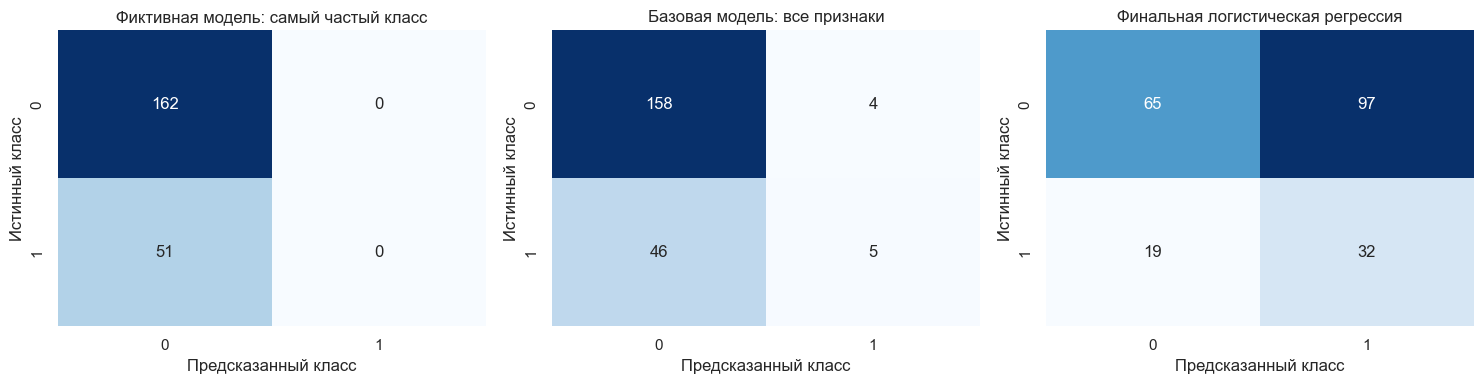

Отчёт по финальной модели на тестовой выборке:


,Точность,Полнота,F1-мера,Количество
Нормальный вес,0.774,0.401,0.528,162.000
Лишний вес,0.248,0.627,0.356,51.000
Доля правильных ответов,0.455,0.455,0.455,0.455
Среднее по классам,0.511,0.514,0.442,213.000
Взвешенное среднее,0.648,0.455,0.487,213.000


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, result in zip(axes, test_results):
    matrix = confusion_matrix(y_test, result['prediction'])
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax)
    ax.set_title(result['Модель'])
    ax.set_xlabel('Предсказанный класс')
    ax.set_ylabel('Истинный класс')
plt.tight_layout()
plt.show()

final_result = test_results[-1]
final_probability = final_result['probability']
final_prediction = final_result['prediction']

print('Отчёт по финальной модели на тестовой выборке:')
display(report_table(y_test, final_prediction))

**Результат финальной проверки.** Фиктивная модель показывает долю правильных ответов около 0.76, но не находит ни одного ребёнка с лишним весом. Базовая модель тоже почти всегда выбирает нормальный вес и находит только несколько детей с лишним весом.

Финальная модель находит 32 из 51 детей с лишним весом, то есть полнота составляет около 0.63. При этом она допускает 97 ложноположительных ошибок, точность составляет около 0.25, а доля правильных ответов падает. Для выбранной постановки это ожидаемая цена снижения числа ложноотрицательных ошибок, но количество лишних тревог слишком велико для практического применения.

ROC-AUC и PR-AUC лишь немного выше случайного уровня. Следовательно, проблема не сводится только к порогу: сами доступные признаки слабо разделяют классы.

## 8. ROC-кривая, кривая «точность-полнота» и вероятности

Порог меняет готовые классы, но не меняет порядок объектов по вероятности. Поэтому отдельно смотрю кривые и распределение вероятностей.

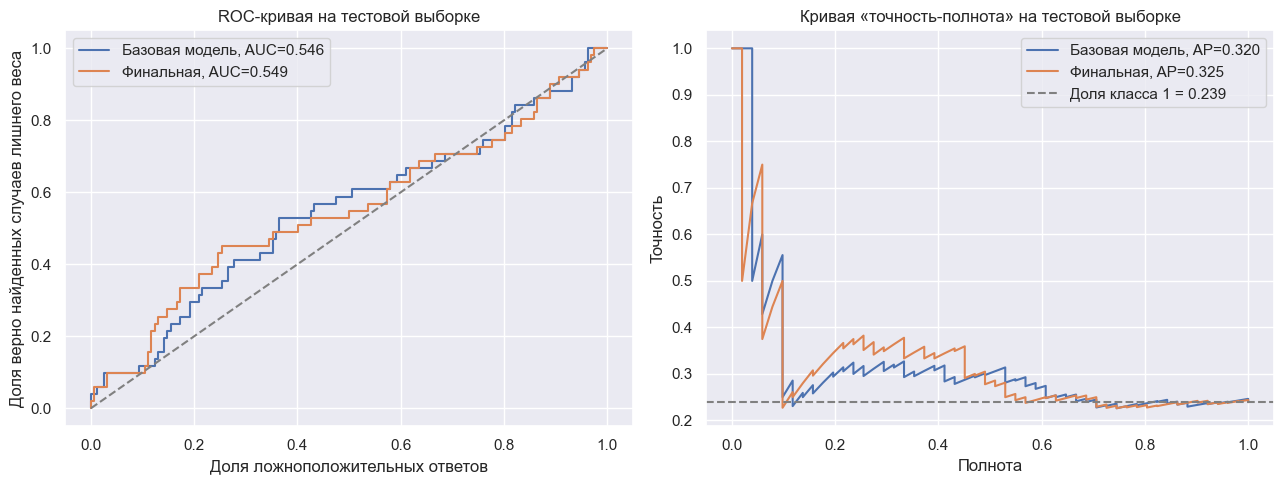

In [14]:
baseline_probability = test_results[1]['probability']

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for label, probability in [
    ('Базовая модель', baseline_probability),
    ('Финальная', final_probability)
]:
    fpr, tpr, _ = roc_curve(y_test, probability)
    axes[0].plot(
        fpr, tpr,
        label=f'{label}, AUC={roc_auc_score(y_test, probability):.3f}'
    )
    precision_curve, recall_curve, _ = precision_recall_curve(
        y_test, probability
    )
    axes[1].plot(
        recall_curve, precision_curve,
        label=f'{label}, AP={average_precision_score(y_test, probability):.3f}'
    )

axes[0].plot([0, 1], [0, 1], '--', color='gray')
axes[0].set_title('ROC-кривая на тестовой выборке')
axes[0].set_xlabel('Доля ложноположительных ответов')
axes[0].set_ylabel('Доля верно найденных случаев лишнего веса')
axes[0].legend()
axes[0].grid(True)

axes[1].axhline(y_test.mean(), linestyle='--', color='gray',
                label=f'Доля класса 1 = {y_test.mean():.3f}')
axes[1].set_title('Кривая «точность-полнота» на тестовой выборке')
axes[1].set_xlabel('Полнота')
axes[1].set_ylabel('Точность')
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

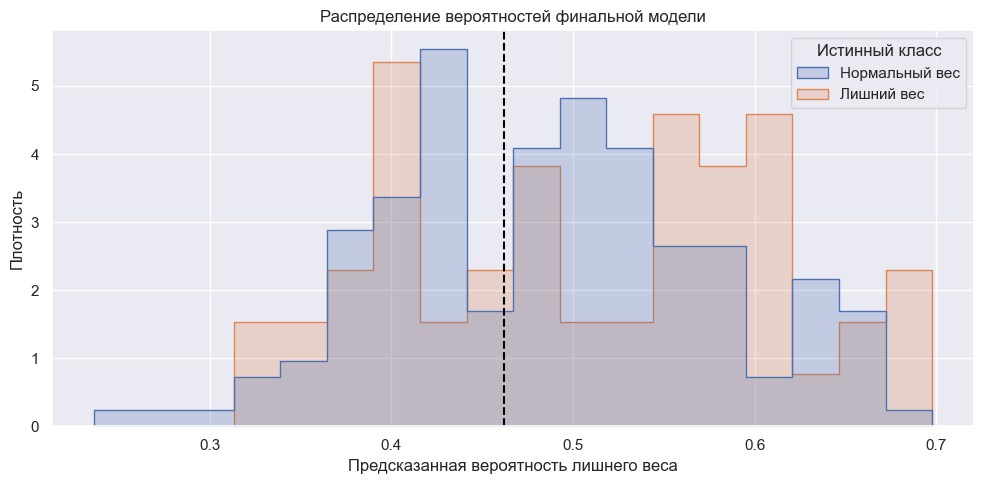

In [15]:
probability_table = pd.DataFrame({
    'Вероятность лишнего веса': final_probability,
    'Истинный класс': y_test.map({0: 'Нормальный вес', 1: 'Лишний вес'}).values
})

plt.figure(figsize=(10, 5))
sns.histplot(
    data=probability_table,
    x='Вероятность лишнего веса', hue='Истинный класс',
    bins=18, element='step', stat='density', common_norm=False
)
plt.axvline(chosen_threshold, color='black', linestyle='--',
            label=f'Порог = {chosen_threshold:.3f}')
plt.title('Распределение вероятностей финальной модели')
plt.xlabel('Предсказанная вероятность лишнего веса')
plt.ylabel('Плотность')
plt.tight_layout()
plt.show()

Распределения оценок двух классов сильно перекрываются. Изменение порога меняет число ложноположительных и ложноотрицательных ошибок, но не улучшает ранжирование. Калибровка вероятностей здесь не проверялась: значения `predict_proba` (метод модели, который возвращает оценки принадлежности объекта к каждому классу) при взвешивании классов нельзя напрямую интерпретировать как индивидуальный риск.

## 9. Анализ ошибок

Сохраняю номера строк из тестовой выборки, чтобы потом можно было найти каждый объект в исходных данных. Сначала рассматриваю ошибки, в которых модель была наиболее уверена, а затем объекты с вероятностью около выбранного порога.

In [16]:
error_table = X_test.copy()
error_table['Истинный класс'] = y_test
error_table['Вероятность'] = final_probability
error_table['Предсказание'] = final_prediction
error_table['Тип'] = np.select(
    [
        (error_table['Истинный класс'] == 1) & (error_table['Предсказание'] == 0),
        (error_table['Истинный класс'] == 0) & (error_table['Предсказание'] == 1)
    ],
    ['Ложноотрицательная ошибка', 'Ложноположительная ошибка'],
    default='Верно'
)
error_table['Расстояние до порога'] = (
    error_table['Вероятность'] - chosen_threshold
).abs()

print(error_table['Тип'].value_counts())

error_columns = [
    'Истинный класс', 'Предсказание', 'Вероятность',
    'sex', 'grade', 'lbweight', 'msmoke',
    'age', 'no2_class', 'no2_home'
]

print()
print('Наиболее уверенные ошибки:')
display(
    error_table[error_table['Тип'] != 'Верно']
    .sort_values('Расстояние до порога', ascending=False)
    [error_columns].head(10).round(3)
)

print()
print('Объекты около порога:')
display(
    error_table.sort_values('Расстояние до порога')
    [error_columns].head(10).round(3)
)

Тип
Верно                        97
Ложноположительная ошибка    97
Ложноотрицательная ошибка    19
Name: count, dtype: int64

Наиболее уверенные ошибки:


,Истинный класс,Предсказание,Вероятность,sex,grade,lbweight,msmoke,age,no2_class,no2_home
1050,0,1,0.697,Male,2nd,Normal birthweight,No smoking,8.753,39.669,57.623
816,0,1,0.666,Female,3rd,Low birthweight,No smoking,8.663,33.912,50.088
571,0,1,0.663,Male,4th,Normal birthweight,No smoking,9.454,35.491,57.490
526,0,1,0.660,Female,2nd,Normal birthweight,No smoking,8.600,18.538,45.174
447,0,1,0.658,Female,2nd,Normal birthweight,No smoking,8.621,30.968,38.111
1044,0,1,0.656,Male,4th,Normal birthweight,No smoking,10.272,41.464,48.563
535,0,1,0.650,Male,2nd,Normal birthweight,No smoking,8.561,18.538,43.476
193,0,1,0.647,Male,4th,Normal birthweight,No smoking,10.031,37.234,38.458
26,0,1,0.638,Female,3rd,Normal birthweight,No smoking,9.268,41.338,41.304
99,0,1,0.635,Male,2nd,Normal birthweight,No smoking,7.923,36.598,69.428



Объекты около порога:


,Истинный класс,Предсказание,Вероятность,sex,grade,lbweight,msmoke,age,no2_class,no2_home
955,0,0,0.459,Female,4th,Normal birthweight,No smoking,10.270,32.419,111.755
489,0,1,0.466,Male,2nd,Low birthweight,No smoking,8.162,52.523,57.454
157,0,1,0.467,Female,3rd,Low birthweight,No smoking,9.139,42.044,56.448
359,0,1,0.468,Male,2nd,Normal birthweight,No smoking,7.921,29.428,64.201
1009,1,1,0.468,Male,4th,Low birthweight,Smoking,9.810,31.456,47.600
553,0,1,0.469,Male,2nd,Normal birthweight,No smoking,7.934,29.002,76.708
37,1,1,0.469,Male,3rd,Normal birthweight,No smoking,9.796,41.338,70.379
566,1,1,0.470,Male,3rd,Normal birthweight,No smoking,8.539,35.491,54.787
280,0,0,0.454,Male,3rd,Low birthweight,No smoking,8.857,28.247,58.304
256,0,0,0.454,Male,3rd,Low birthweight,Smoking,8.526,20.647,28.280


In [17]:
group_rows = []
for column in ['sex', 'grade']:
    grouped = error_table.groupby(column).agg(
        Объектов=('Тип', 'size'),
        Истинный_лишний_вес=('Истинный класс', 'sum'),
        Предсказанный_лишний_вес=('Предсказание', 'sum'),
        Ошибок=('Тип', lambda values: (values != 'Верно').sum())
    )
    grouped['Доля ошибок'] = grouped['Ошибок'] / grouped['Объектов']
    grouped.insert(0, 'Группа', column)
    grouped.insert(1, 'Значение', grouped.index)
    group_rows.append(grouped.reset_index(drop=True))

group_errors = pd.concat(group_rows, ignore_index=True)
group_errors.round(3)

,Группа,Значение,Объектов,Истинный_лишний_вес,Предсказанный_лишний_вес,Ошибок,Доля ошибок
0,sex,Female,100,24,53,49,0.490
1,sex,Male,113,27,76,67,0.593
2,grade,2nd,79,18,50,48,0.608
3,grade,3rd,77,21,49,42,0.545
4,grade,4th,57,12,30,26,0.456


Ошибки есть во всех группах. В некоторых группах их больше, но тестовая выборка небольшая, а модель работает не очень хорошо. Поэтому по этой таблице нельзя делать серьёзные выводы о детях или качестве модели для отдельных групп. Многие дети с нормальным и лишним весом имеют похожие признаки, из-за чего модели сложно правильно разделить их на два класса.

## 10. Коэффициенты финальной модели

Числовые признаки приведены к одному масштабу, поэтому их коэффициенты можно сравнивать между собой. Категориальные признаки после кодирования разделены на отдельные столбцы, и каждый из них получает свой коэффициент. Положительный коэффициент увеличивает вероятность лишнего веса, а отрицательный уменьшает. При этом модель показывает только связь между признаками и результатом, но не доказывает, что один признак является причиной другого.

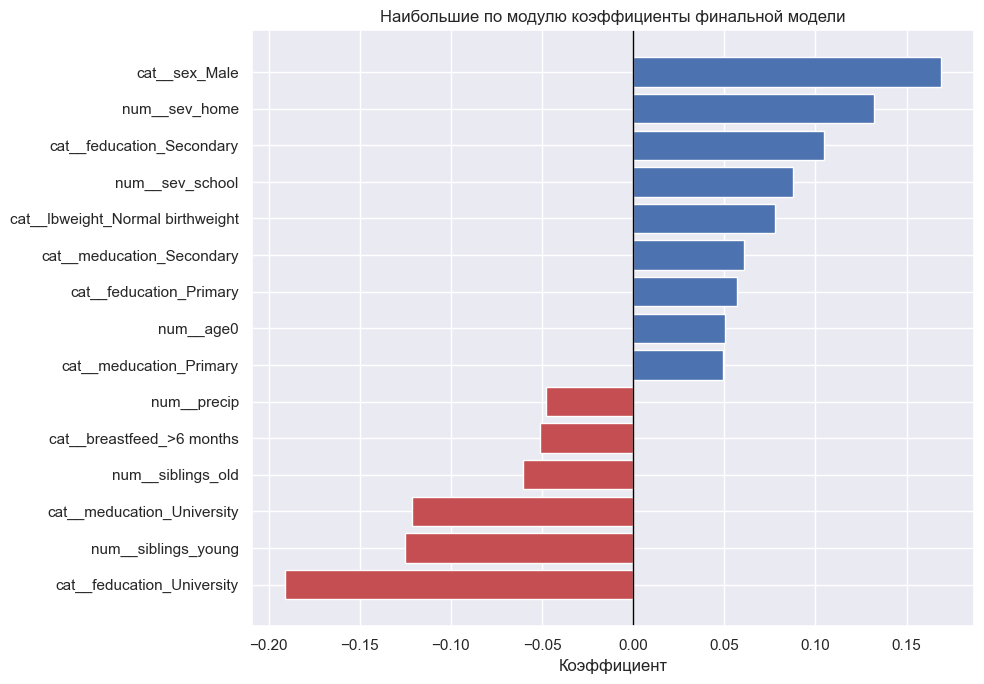

,Признак,Коэффициент
27,cat__feducation_University,-0.191
5,num__siblings_young,-0.125
23,cat__meducation_University,-0.121
4,num__siblings_old,-0.060
17,cat__breastfeed_>6 months,-0.051
10,num__precip,-0.048
21,cat__meducation_Primary,0.050
3,num__age0,0.050
25,cat__feducation_Primary,0.057
22,cat__meducation_Secondary,0.061


In [18]:
feature_names = final_model['preprocessors'].get_feature_names_out()
coefficients = final_model['model'].coef_[0]
coefficient_table = pd.DataFrame({
    'Признак': feature_names,
    'Коэффициент': coefficients
})
coefficient_table['Модуль'] = coefficient_table['Коэффициент'].abs()

important = (
    coefficient_table.nlargest(15, 'Модуль')
    .sort_values('Коэффициент')
)

plt.figure(figsize=(10, 7))
colors = ['#c44e52' if value < 0 else '#4c72b0'
          for value in important['Коэффициент']]
plt.barh(important['Признак'], important['Коэффициент'], color=colors)
plt.axvline(0, color='black', linewidth=1)
plt.title('Наибольшие по модулю коэффициенты финальной модели')
plt.xlabel('Коэффициент')
plt.ylabel('')
plt.tight_layout()
plt.show()

important[['Признак', 'Коэффициент']].round(3)

Самые заметные коэффициенты связаны с полом, образованием родителей, социальными индексами и числом братьев или сестёр. В модели используется сильная L2-регуляризация (`C=0.01`), которая штрафует большие коэффициенты. Редкие категории и связанные признаки могут делать отдельные оценки неустойчивыми, поэтому их нельзя трактовать как медицинские или причинные выводы.

## 11. Пограничные и новые объекты

Возьму шесть реальных объектов тестовой выборки, для которых вероятность ближе всего к порогу. Они не используются для изменения модели. Затем создаю ещё две строки на основе самого пограничного объекта:

- в одной убираю значения `no2_home` и `breastfeed`, чтобы проверить заполнение пропусков
- во второй ставлю большие, но встречавшиеся в обучающей выборке значения `no2_home` и `sev_home`

У изменённых строк нет истинного класса. Это только проверка поведения готового конвейера `Pipeline`.

In [19]:
border_positions = np.argsort(
    np.abs(final_probability - chosen_threshold)
)[:6]
border_objects = X_test.iloc[border_positions].copy()
border_names = [f'Реальный пограничный {i}' for i in range(1, 7)]

missing_object = border_objects.iloc[[0]].copy()
missing_object['no2_home'] = np.nan
missing_object['breastfeed'] = np.nan

high_object = border_objects.iloc[[0]].copy()
high_object['no2_home'] = X_train['no2_home'].max()
high_object['sev_home'] = X_train['sev_home'].max()

new_objects = pd.concat(
    [border_objects, missing_object, high_object],
    ignore_index=True
)
object_names = border_names + [
    'Новый: два пропуска',
    'Новый: большие значения среды'
]

new_probability = final_model.predict_proba(new_objects)[:, 1]
new_prediction = (new_probability >= chosen_threshold).astype(int)

new_results = new_objects[[
    'sex', 'grade', 'age', 'no2_class', 'no2_home',
    'sev_home', 'lbweight', 'breastfeed'
]].copy()
new_results.insert(0, 'Объект', object_names)
new_results['Вероятность лишнего веса'] = new_probability
new_results['Предсказанный класс'] = np.where(
    new_prediction == 1, 'Лишний вес', 'Нормальный вес'
)
new_results.round(3)

,Объект,sex,grade,age,no2_class,no2_home,sev_home,lbweight,breastfeed,Вероятность лишнего веса,Предсказанный класс
0,Реальный пограничный 1,Female,4th,10.270,32.419,111.755,0.548,Normal birthweight,No breastfeeding,0.459,Нормальный вес
1,Реальный пограничный 2,Male,2nd,8.162,52.523,57.454,0.226,Low birthweight,<6 months,0.466,Лишний вес
2,Реальный пограничный 3,Female,3rd,9.139,42.044,56.448,0.452,Low birthweight,No breastfeeding,0.467,Лишний вес
3,Реальный пограничный 4,Male,2nd,7.921,29.428,64.201,0.226,Normal birthweight,<6 months,0.468,Лишний вес
4,Реальный пограничный 5,Male,4th,9.810,31.456,47.600,0.419,Low birthweight,No breastfeeding,0.468,Лишний вес
5,Реальный пограничный 6,Male,2nd,7.934,29.002,76.708,0.258,Normal birthweight,No breastfeeding,0.469,Лишний вес
6,Новый: два пропуска,Female,4th,10.270,32.419,NaN,0.548,Normal birthweight,NaN,0.477,Лишний вес
7,Новый: большие значения среды,Female,4th,10.270,32.419,118.657,0.968,Normal birthweight,No breastfeeding,0.526,Лишний вес


In [20]:
checks = pd.DataFrame({
    'Проверка': [
        'Обучающая и тестовая выборки не пересекаются',
        'Доли лишнего веса в двух выборках близки',
        'Вероятности тестовой выборки конечны',
        'Вероятности находятся от 0 до 1',
        'Обработано 8 пограничных или новых объектов',
        'Новые объекты преобразуются без ошибки'
    ],
    'Пройдена': [
        len(X_train.index.intersection(X_test.index)) == 0,
        abs(y_train.mean() - y_test.mean()) < 0.01,
        np.isfinite(final_probability).all(),
        ((final_probability >= 0) & (final_probability <= 1)).all(),
        len(new_objects) == 8,
        np.isfinite(new_probability).all()
    ]
})
checks

,Проверка,Пройдена
0,Обучающая и тестовая выборки не пересекаются,True
1,Доли лишнего веса в двух выборках близки,True
2,Вероятности тестовой выборки конечны,True
3,Вероятности находятся от 0 до 1,True
4,Обработано 8 пограничных или новых объектов,True
5,Новые объекты преобразуются без ошибки,True


**Вывод по новым объектам.** У выбранных строк оценки ближе всего к порогу, поэтому небольшого изменения оценки достаточно для смены класса. Устойчивость к малым изменениям признаков отдельно не проверялась. Конвейер обработки технически справляется с пропусками и большими значениями, но это не доказывает правильность таких прогнозов. Для необычных объектов особенно важно не воспринимать вероятность как точный медицинский риск.

## 12. Итоговые выводы и обсуждение

**Что оказалось неожиданным.** Высокая доля правильных ответов сама по себе оказалась обманчивой. Фиктивная и базовая модели часто выбирали нормальный вес и поэтому почти не находили детей с лишним весом. Модель с одним признаком `sex` тоже почти повторила фиктивную модель: в признаке был небольшой сигнал, но его оказалось недостаточно для полезного результата.

**Проверка гипотез.**

1. В обучающей выборке лишний вес встречался у 28,3% мальчиков и у 20,1% девочек. Различие в этой выборке есть, но по нему нельзя утверждать, что пол является причиной лишнего веса.
2. Добавление категориальных признаков немного улучшило разделение классов по сравнению с моделью только на числовых признаках. Эта гипотеза подтвердилась частично, потому что общее качество всё равно осталось невысоким.
3. Взвешивание классов помогло находить больше детей с лишним весом, но одновременно заметно увеличило число ложных тревог. Гипотеза подтвердилась, но улучшение одной характеристики ухудшило другие.
4. Изменение параметра `C` почти не повлияло на результат. Различия между вариантами были сопоставимы с разбросом между разбиениями, поэтому гипотеза о заметной пользе изменения силы регуляризации не подтвердилась.
5. После снижения порога с 0,5 до примерно 0,46 модель стала находить больше детей с лишним весом, но начала чаще ошибочно относить к этой группе детей с нормальным весом. Эта гипотеза подтвердилась.

**Признаки модели.** Наиболее заметные коэффициенты получились у пола, образования родителей, числа братьев и сестёр и социальных характеристик района. Однако коэффициенты показывают только связи, которые нашла модель. Они не доказывают, что эти признаки являются причинами лишнего веса. Из-за слабого качества модели нельзя уверенно назвать какой-то один признак действительно важным.

**Ограничения модели.** Значения, которые модель выдаёт для детей с нормальным и лишним весом, сильно пересекаются. Это означает, что по выбранным признакам логистической регрессии трудно разделить два класса. Возможно, в данных недостаточно нужной информации или зависимости между признаками сложнее линейной границы.

**Можно ли доверять вероятностям.** Полученные значения показывают уверенность модели и помогают выбрать порог. Их нельзя воспринимать как точную вероятность лишнего веса или медицинскую оценку риска, потому что модель работает слабо, использует взвешивание классов, а точность вероятностей отдельно не проверялась.

**Что можно попробовать дальше.** Можно сравнить результат с деревом решений или другой нелинейной моделью на тех же разбиениях данных. Это покажет, сможет ли более сложная граница лучше разделить классы. Также полезно проверить результат на другой выборке. Перед добавлением веса, роста или индекса массы тела нужно выяснить, как был сформирован столбец `overweight`. Если целевой столбец рассчитан из этих показателей, модель фактически получит готовый ответ среди признаков, и оценка качества будет завышена.